# 07 · Run on video

Goal: run the detector frame after frame, watch it live, measure it against the truth, then try other footage.

In [1]:
%load_ext autoreload
%autoreload 2
import math
import numpy as np
import matplotlib.pyplot as plt
from helpers import SyntheticTrack, synthetic_drive, show, table, use_style
use_style()

from helpers import DATA_DIR, iter_frames, play
from lanedet.camera import Camera
from lanedet.detector import LaneDetector

base = SyntheticTrack()
det = LaneDetector(Camera(base.width, base.height, base.focal, base.cam_height, base.v_horizon))

## Overlay block

Draws on an upscaled copy: bands (cyan near, orange far), blobs (white ×), band centres (dots), centreline chord (yellow), status line.

This cell saves the block to `lanedet/overlay.py`. The next cell imports it.

In [2]:
%%writefile lanedet/overlay.py
"""Block 6 - overlay: draw what the detector saw on top of the frame."""

import math

import cv2
import numpy as np

CYAN, ORANGE, YELLOW, WHITE, GREY = (0, 220, 255), (255, 150, 0), (255, 235, 0), (240, 240, 240), (120, 120, 120)


def draw(frame: np.ndarray, det, detector, scale: int = 4) -> np.ndarray:
    """Frame | mask side by side, upscaled, with bands, blobs, centre points, centreline and a status line."""
    H, W = frame.shape[:2]
    cam = cv2.resize(frame, (W * scale, H * scale), interpolation=cv2.INTER_NEAREST)
    mask_rgb = (np.stack([det.mask] * 3, -1) * 255).astype(np.uint8)
    msk = cv2.resize(mask_rgb, (W * scale, H * scale), interpolation=cv2.INTER_NEAREST)
    s = scale

    pts = []
    for img in (cam, msk):
        cv2.line(img, (W * s // 2, 0), (W * s // 2, H * s), GREY, 1)
        for est, rows, colour in ((det.near, detector.near_rows, CYAN), (det.far, detector.far_rows, ORANGE)):
            cv2.rectangle(img, (0, rows[0] * s), (W * s - 1, rows[1] * s), colour, 1)
            v = detector.band_row(rows)
            for line in est.used:
                cv2.drawMarker(img, (int(line.u * s), int(v * s)), WHITE, cv2.MARKER_TILTED_CROSS, 10, 2)
            if est.u is not None:
                cv2.circle(img, (int(est.u * s), int(v * s)), 5, colour, -1)
        x_n, x_f = det.x_near, det.x_far
        v_n, v_f = detector.band_row(detector.near_rows), detector.band_row(detector.far_rows)
        pts = [(int(detector.camera.to_pixel_u(x, v) * s), int(v * s)) for x, v in ((x_n, v_n), (x_f, v_f))]
        cv2.line(img, pts[0], pts[1], YELLOW, 2, cv2.LINE_AA)

    strip = np.full((26, W * s * 2, 3), 20, dtype=np.uint8)
    text = (
        f"e_lat {det.e_lat:+.2f}   e_heading {math.degrees(det.e_heading):+.1f} deg   "
        f"conf {det.confidence:.2f}   near {det.near.case}   far {det.far.case}"
    )
    cv2.putText(strip, text, (8, 18), cv2.FONT_HERSHEY_SIMPLEX, 0.5, WHITE, 1, cv2.LINE_AA)
    return np.vstack([np.hstack([cam, msk]), strip])

Writing lanedet/overlay.py


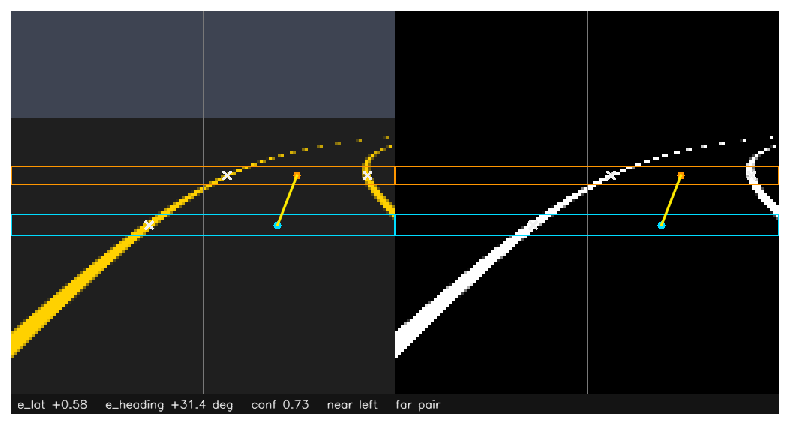

In [3]:
from lanedet.overlay import draw

frame = SyntheticTrack(offset=0.05, yaw=0.1, curvature=0.8).render()
plt.figure(figsize=(9, 5))
plt.imshow(draw(frame, det(frame), det))
plt.axis("off")
plt.show()

## Live

Plays in place; interrupt the kernel to stop. `record_to` also writes an mp4 into `labs/data/`.

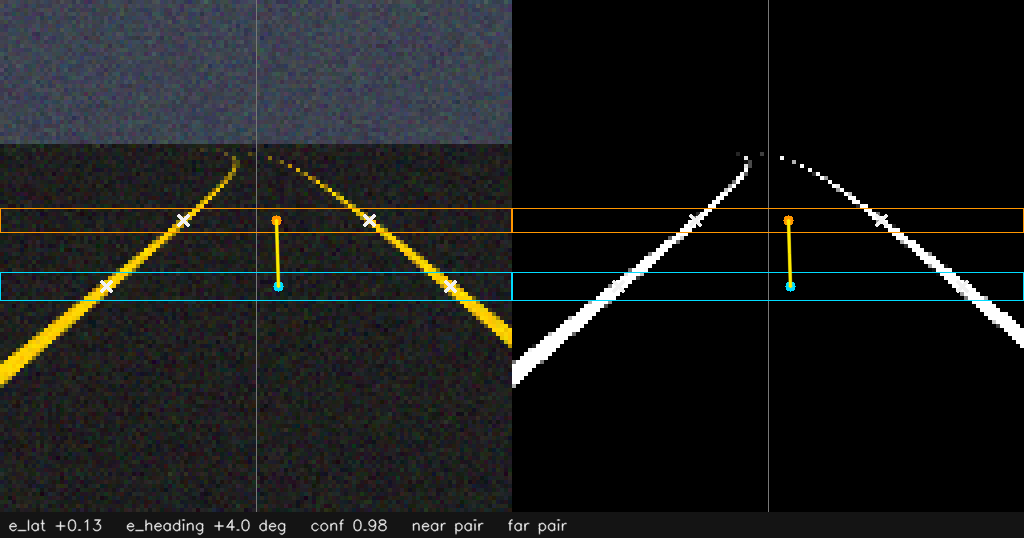

In [4]:
det.reset()
n_frames = play(
    (frame for frame, _ in synthetic_drive(150, noise=8)),
    render=lambda f: draw(f, det(f), det),
    fps=20,
    record_to="data/synthetic_drive.mp4",
)

## Against the truth

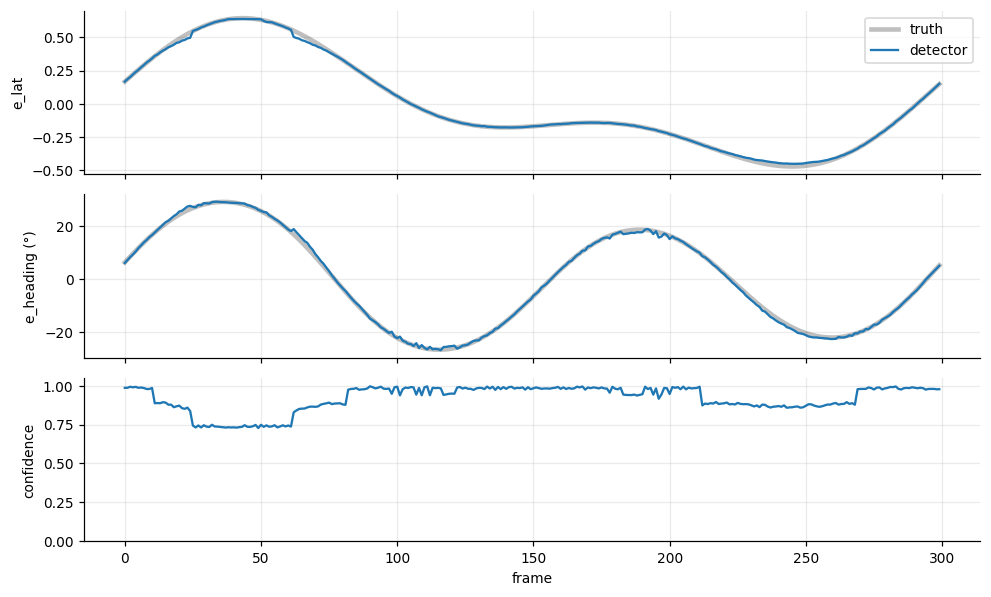

e_lat RMSE,e_heading RMSE (°),both bands paired,ms / frame (median)
0.010,0.578,88%,0.081


In [5]:
import time

det.reset()
zn = float(det.camera.distance(det.band_row(det.near_rows)))
zf = float(det.camera.distance(det.band_row(det.far_rows)))
log = {k: [] for k in ("e_lat", "true_lat", "e_head", "true_head", "conf", "ms", "cases")}
for frame, tr in synthetic_drive(300, noise=8):
    t0 = time.perf_counter()
    d = det(frame)
    log["ms"].append((time.perf_counter() - t0) * 1e3)
    xn, xf = tr.centre_x(zn), tr.centre_x(zf)
    log["e_lat"].append(d.e_lat)
    log["true_lat"].append(xn / tr.half_width)
    log["e_head"].append(math.degrees(d.e_heading))
    log["true_head"].append(math.degrees(math.atan2(xf - xn, zf - zn)))
    log["conf"].append(d.confidence)
    log["cases"].append(f"{d.near.case}/{d.far.case}")

fig, ax = plt.subplots(3, 1, figsize=(9, 5.5), sharex=True)
ax[0].plot(log["true_lat"], "k", lw=3, alpha=0.25, label="truth")
ax[0].plot(log["e_lat"], label="detector")
ax[0].set_ylabel("e_lat")
ax[0].legend(loc="upper right")
ax[1].plot(log["true_head"], "k", lw=3, alpha=0.25)
ax[1].plot(log["e_head"])
ax[1].set_ylabel("e_heading (°)")
ax[2].plot(log["conf"])
ax[2].set(ylabel="confidence", xlabel="frame", ylim=(0, 1.05))
plt.tight_layout()
plt.show()

err_lat = np.subtract(log["e_lat"], log["true_lat"])
err_head = np.subtract(log["e_head"], log["true_head"])
table([{
    "e_lat RMSE": float(np.sqrt(np.mean(err_lat ** 2))),
    "e_heading RMSE (°)": float(np.sqrt(np.mean(err_head ** 2))),
    "both bands paired": f"{log['cases'].count('pair/pair') / len(log['cases']):.0%}",
    "ms / frame (median)": float(np.median(log["ms"])),
}])

Confidence drops to 0.75 when one band runs on a single line and to 0.5 when both do; the error stays small because the prior from the last frame is good.

## Other footage

Put a clip in `labs/data/` and set `SOURCE`, or use a webcam index (`SOURCE = 0`). Metres need a calibrated camera: measure height and FOV, find the horizon as in 04, choose the bands for that geometry. Without calibration the overlay still shows whether the mask and blobs are right.

In [6]:
SOURCE = DATA_DIR / "my_clip.mp4"  # or 0 for a webcam, or a folder of PNG frames

real_det = LaneDetector(Camera(width=128, height=128, focal=64.0, cam_height=0.25, v_horizon=35.8))  # your calibration
if isinstance(SOURCE, int) or SOURCE.exists():
    n_frames = play(iter_frames(SOURCE, max_frames=600), render=lambda f: draw(f, real_det(f), real_det), fps=20)

## Check

In [7]:
assert np.sqrt(np.mean(err_lat ** 2)) < 0.03
assert np.sqrt(np.mean(err_head ** 2)) < 1.5
assert (DATA_DIR / "synthetic_drive.mp4").exists()

## Exercises

1. Record frames from the Isaac sim: save `camera.data.output["rgb"][0]` as PNGs into `labs/data/sim_frames/` and set `SOURCE = DATA_DIR / "sim_frames"`.
2. Add exponential smoothing to `e_heading`. Plot its RMSE against the smoothing factor.